In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score,
    roc_curve
)

from xgboost import XGBClassifier

df = pd.read_csv("customer_churn.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Exploratory data analysis

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


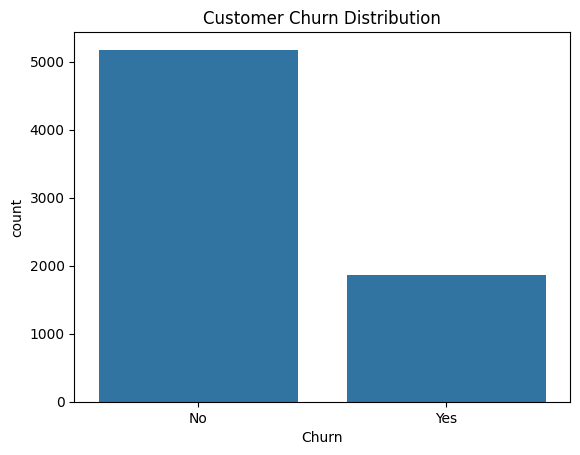

In [2]:
print(df.info())
print(df.isnull().sum())
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

In [3]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [4]:
df.drop("customerID", axis=1, inplace=True)  # Remove customer ID

df["TotalCharges"] = pd.to_numeric(          # Convert TotalCharges to numeric
    df["TotalCharges"], errors="coerce"
)

X = df.drop("Churn", axis=1)                 # Separate features and target
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Missing values in TotalCharges:", X["TotalCharges"].isnull().sum())
print("Target distribution:\n", y.value_counts())

Missing values in TotalCharges: 11
Target distribution:
 Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


# PipeLine

In [7]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [8]:
# Calculate class imbalance ratio using training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Scale pos weight:", scale_pos_weight)

Scale pos weight: 2.768561872909699


### Random Forest 

In [9]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

### XGBoost

In [10]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

In [11]:
rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

print("Random Forest ROC-AUC:", round(rf_auc, 4))
print("XGBoost ROC-AUC:", round(xgb_auc, 4))

print("\nRandom Forest Classification Report")
print(classification_report(y_test, rf_predictions))

print("\nXGBoost Classification Report")
print(classification_report(y_test, xgb_predictions))

Random Forest ROC-AUC: 0.8284
XGBoost ROC-AUC: 0.84

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.86      0.85      0.85      1035
           1       0.59      0.60      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409


XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv = cross_val_score(
    rf_model, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

xgb_cv = cross_val_score(
    xgb_model, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

print("Random Forest CV ROC-AUC:", rf_cv.mean())
print("XGBoost CV ROC-AUC:", xgb_cv.mean())

Random Forest CV ROC-AUC: 0.8330110502364626
XGBoost CV ROC-AUC: 0.8442966155012108


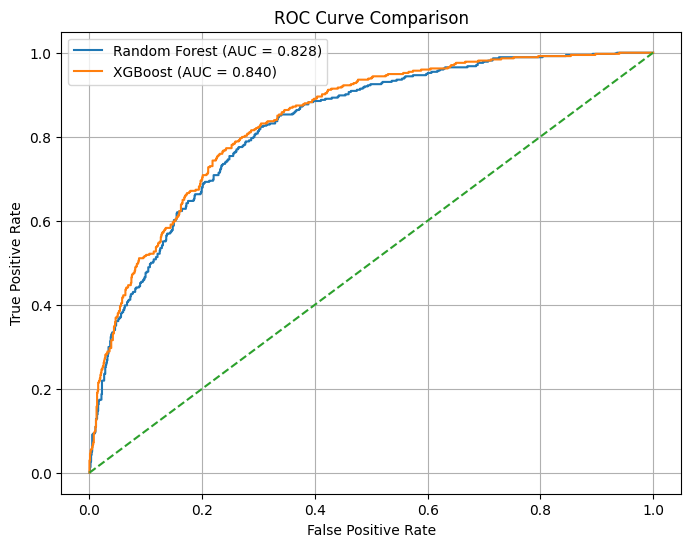

In [13]:
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

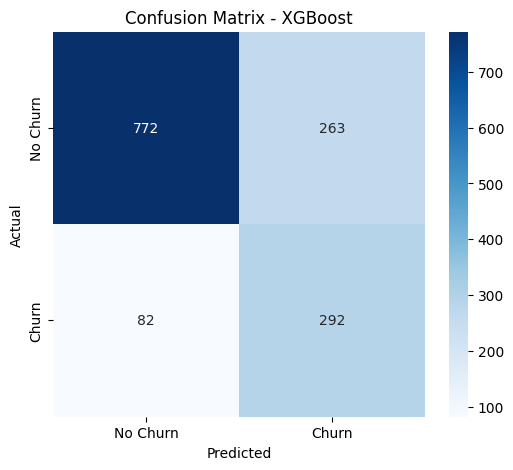

In [14]:
best_model_name = (
    "Random Forest" if rf_auc >= xgb_auc else "XGBoost"
)

best_model = rf_model if rf_auc >= xgb_auc else xgb_model

best_predictions = (
    rf_predictions if rf_auc >= xgb_auc else xgb_predictions
)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

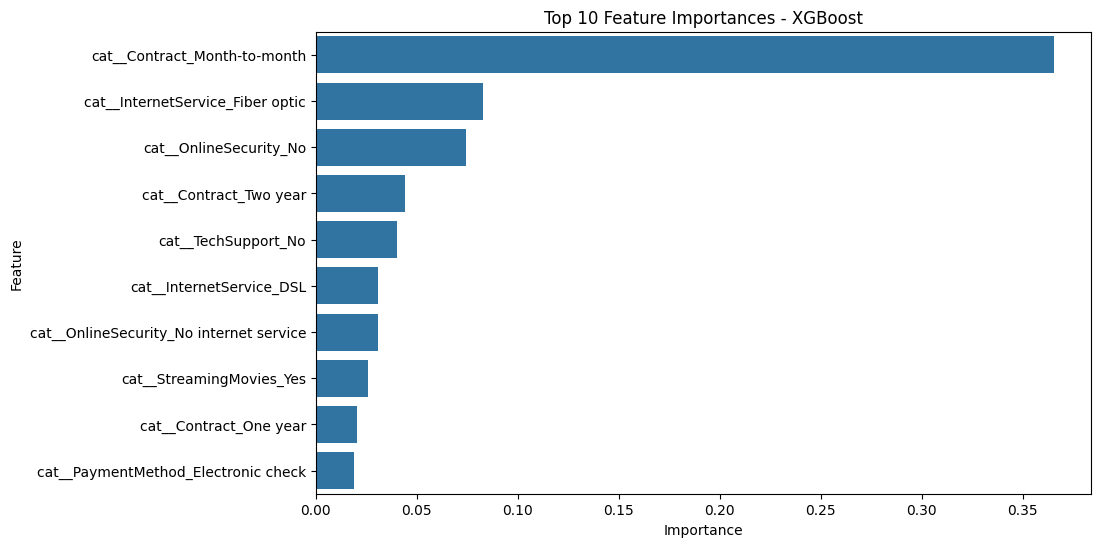

,Feature,Importance
36,cat__Contract_Month-to-month,0.365395
16,cat__InternetService_Fiber optic,0.083016
18,cat__OnlineSecurity_No,0.074493
38,cat__Contract_Two year,0.044125
27,cat__TechSupport_No,0.040357
15,cat__InternetService_DSL,0.031045
19,cat__OnlineSecurity_No internet service,0.030633
35,cat__StreamingMovies_Yes,0.025992
37,cat__Contract_One year,0.020413
43,cat__PaymentMethod_Electronic check,0.018783


In [15]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title(f"Top 10 Feature Importances - {best_model_name}")
plt.show()

display(importance_df)

In [16]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Test ROC-AUC": [rf_auc, xgb_auc],
    "CV ROC-AUC": [rf_cv.mean(), xgb_cv.mean()]
})

display(comparison)

print("Best Model:", best_model_name)

,Model,Test ROC-AUC,CV ROC-AUC
0,Random Forest,0.828385,0.833011
1,XGBoost,0.839974,0.844297


Best Model: XGBoost


Random Forest and XGBoost were trained to predict customer churn using telecom subscription data. Data preprocessing, categorical encoding, and class weighting were applied to handle data quality and class imbalance. Both models were evaluated using ROC-AUC, confusion matrix, and cross-validation. Feature importance analysis identified key factors influencing churn. The project demonstrates how machine learning can help telecom companies identify at-risk customers and improve customer retention.